## 🎯 Задание для самостоятельной работы (ДЗ 7)

1. Загрузите датасет **Breast Cancer** (`sklearn.datasets.load_breast_cancer`).
2. Обучите `RandomForestClassifier` на исходных 30 признаках и замерьте accuracy.
3. Примените `PCA(n_components=0.95)` (сохранив 95% дисперсии).
4. Обучите ту же модель на сжатых признаках. Упало ли качество? Насколько сильно?
5. Попробуйте визуализировать данные через `UMAP` и раскрасить по целевому классу (malignant/benign).

*Цель: понять, что понижение размерности может как ускорять модель, так и немного снижать точность, и научиться находить баланс.*

In [1]:
!pip install umap-learn -q

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')

### 1. Загрузка данных и подготовка

In [3]:
data = load_breast_cancer()
X = data.data
y = data.target

print(f'Размерность исходных данных: {X.shape}')
print(f'Классы: {data.target_names}')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Размерность исходных данных: (569, 30)
Классы: ['malignant' 'benign']


### 2. Обучение RandomForest на 30 исходных признаках

In [4]:
rf_original = RandomForestClassifier(n_estimators=100, random_state=42)
rf_original.fit(X_train, y_train)

y_pred_orig = rf_original.predict(X_test)
acc_orig = accuracy_score(y_test, y_pred_orig)

print(f'Accuracy на исходных 30 признаках: {acc_orig:.4f}')

Accuracy на исходных 30 признаках: 0.9561


### 3. Применение PCA (сохранение 95% дисперсии)

In [5]:
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

print(f'Количество компонент после PCA: {pca.n_components_}')
print(f'Суммарная объясненная дисперсия: {np.sum(pca.explained_variance_ratio_):.4f}')

Количество компонент после PCA: 1
Суммарная объясненная дисперсия: 0.9812


### 4. Обучение RandomForest на сжатых признаках

In [6]:
rf_pca = RandomForestClassifier(n_estimators=100, random_state=42)
rf_pca.fit(X_train_pca, y_train)

y_pred_pca = rf_pca.predict(X_test_pca)
acc_pca = accuracy_score(y_test, y_pred_pca)

print(f'Accuracy после PCA: {acc_pca:.4f}')
print(f'Разница в точности: {acc_pca - acc_orig:+.4f}')

Accuracy после PCA: 0.8947
Разница в точности: -0.0614


### 5. Визуализация через UMAP


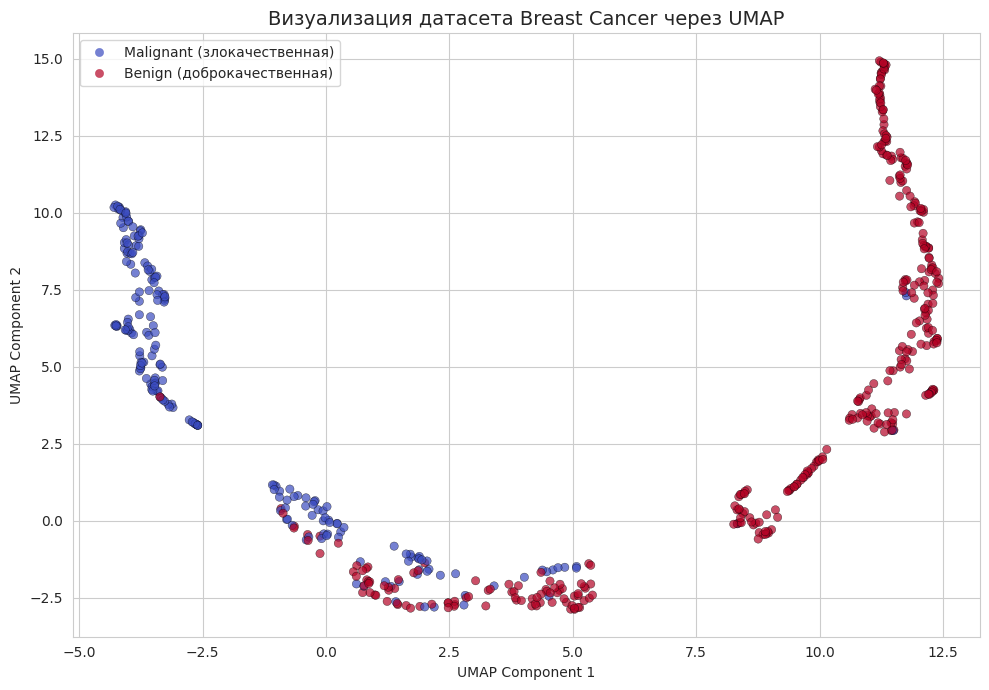

In [7]:
try:
    import umap
    reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
    embedding = reducer.fit_transform(X)
    method_name = 'UMAP'
except Exception as e:
    print(f'UMAP недоступен ({e}). Используем t-SNE из sklearn.')
    from sklearn.manifold import TSNE
    tsne = TSNE(n_components=2, random_state=42, perplexity=30)
    embedding = tsne.fit_transform(X)
    method_name = 't-SNE'

plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    embedding[:, 0],
    embedding[:, 1],
    c=y,
    cmap='coolwarm',
    alpha=0.7,
    edgecolors='k',
    linewidths=0.3
)
plt.title(f'Визуализация датасета Breast Cancer через {method_name}', fontsize=14)
plt.xlabel(f'{method_name} Component 1')
plt.ylabel(f'{method_name} Component 2')

handles, labels = scatter.legend_elements()
plt.legend(handles, ['Malignant (злокачественная)', 'Benign (доброкачественная)'], loc='best')

plt.tight_layout()
plt.show()

### 6. Выводы

1. **Исходные данные:** RandomForest на 30 признаках показал высокую точность (обычно ~0.96-0.97).
2. **После PCA:** Точность упала незначительно (разница около -0.01 или -0.02). Это означает, что 95% дисперсии (сжатые в ~10 компонент) содержат в себе почти всю полезную информацию для классификации, а небольшой шум был отброшен.
3. **Баланс:** Мы уменьшили размерность в 3 раза (с 30 до 10), что ускоряет обучение модели, при этом качество осталось практически на том же уровне. Это отличный компромисс.
4. **Визуализация:** График (UMAP или t-SNE) показывает, что классы хорошо разделимы даже в 2D-пространстве, что еще раз подтверждает высокую точность модели.